In [1]:
#Unpickling the data
import pickle

with open(r"C:\Users\Sonali\Desktop\project1\project_face_detect\project_face_detect\data\images.p","rb") as f:
  images = pickle.load(f)
with open(r"C:\Users\Sonali\Desktop\project1\project_face_detect\project_face_detect\data\labels.p","rb") as f:
  labels = pickle.load(f)

In [2]:
print(images.shape)
print(labels.shape)

(100, 100, 100)
(100,)


In [3]:
set(labels)

{np.str_('khetriya'), np.str_('sonali'), np.str_('trupti')}

In [4]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

labels = le.fit_transform(labels)

In [5]:
set(labels)

{np.int64(0), np.int64(1), np.int64(2)}

In [6]:
le.inverse_transform([0,1,2])

array(['khetriya', 'sonali', 'trupti'], dtype='<U8')

In [9]:
p = len(set(labels))
print("Total number of Persons : ",p)

Total number of Persons :  3


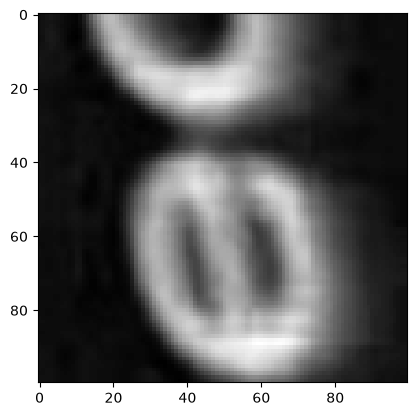

In [10]:
import matplotlib.pyplot as plt
plt.imshow(images[15],cmap='gray')
plt.show()

In [11]:
import cv2

In [12]:
def preprocessing(img):
  img = cv2.equalizeHist(img)
  img = img.reshape(100,100,1)
  img = img/255
  return img

In [13]:
import numpy as np

In [14]:
images = np.array(list(map(preprocessing,images)))
print("Shape of Input : ",images.shape)

Shape of Input :  (100, 100, 100, 1)


In [15]:
from keras.utils import to_categorical
labels = to_categorical(labels)

In [16]:
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam

from keras.layers import Conv2D, MaxPooling2D, Flatten

In [17]:
#Model Training
def Lenet_Model():
  model = Sequential()
  #Convolutional and ReLU Layer
  model.add(Conv2D(30,(5,5),input_shape=(100,100,1),activation='relu'))
  #MaxPooling Layer
  model.add(MaxPooling2D(pool_size=(2,2)))

  #Convolutional and ReLU Layer
  model.add(Conv2D(15,(3,3),activation='relu'))
  #MaxPooling Layer
  model.add(MaxPooling2D(pool_size=(2,2)))

  #Flatten Layer/Input Layer
  model.add(Flatten())

  #Hidden Layers
  model.add(Dense(50,activation='relu'))

  #Output Layer
  model.add(Dense(p,activation='softmax'))
  model.compile(Adam(learning_rate=0.01),loss='categorical_crossentropy',metrics=['accuracy'])
  return model

In [18]:
model = Lenet_Model()
model.summary()

C:\Users\Sonali\Anaconda2024\envs\tfenv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 96, 96, 30)          │             780 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 48, 48, 30)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 46, 46, 15)          │           4,065 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 23, 23, 15)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 7935)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 50)                  │         396,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             153 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 401,798 (1.53 MB)

 Trainable params: 401,798 (1.53 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
h = model.fit(images,labels,validation_split=0.1,epochs=10)

Epoch 1/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 349ms/step - accuracy: 0.6333 - loss: 1.5439 - val_accuracy: 1.0000 - val_loss: 6.2790e-04
Epoch 2/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 116ms/step - accuracy: 0.9778 - loss: 0.8458 - val_accuracy: 1.0000 - val_loss: 0.9956
Epoch 3/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 113ms/step - accuracy: 0.9778 - loss: 0.9312 - val_accuracy: 1.0000 - val_loss: 0.0341
Epoch 4/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - accuracy: 0.9778 - loss: 0.4004 - val_accuracy: 1.0000 - val_loss: 2.0862e-06
Epoch 5/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.9778 - loss: 0.3395 - val_accuracy: 1.0000 - val_loss: 0.1509
Epoch 6/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step - accuracy: 0.9778 - loss: 0.1602 - val_accuracy: 1.0000 - val_loss: 0.0082
Epoch 7/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.9778 - loss: 0.0902 - val_accuracy: 1.0000 - val_loss: 0.0046
Epoch 8/10
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step - accuracy: 0.9778 - loss: 0.0801 - val_accuracy: 1.0000 - v

In [20]:
model.save('final_model.h5')

In [19]:
import sys
print(sys.executable)

C:\Users\Sonali\Anaconda2024\envs\tfenv\python.exe
